In [3]:
# ==============================
# 1. IMPORT LIBRARIES
# ==============================

import pandas as pd
import numpy as np
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

In [4]:
# =================================
# 2. LOAD DATASET
# =================================

from datasets import load_dataset
import pandas as pd

dataset = load_dataset("med2425/resume-job-fit-merged-v1")

# Convert Hugging Face datasets to pandas
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Dataset loaded successfully")
print("Train:", train_df.shape)
print("Test:", test_df.shape)

README.md:   0%|          | 0.00/2.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  129MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  128MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 43.9MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/80017 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/13716 [00:00<?, ? examples/s]

Dataset loaded successfully
Train: (80017, 6)
Test: (13716, 6)


In [48]:
!pip install -q datasets

In [49]:
dataset


DatasetDict({
    train: Dataset({
        features: ['resume', 'jd', 'label', 'source', 'resume_domain', 'jd_domain'],
        num_rows: 80017
    })
    test: Dataset({
        features: ['resume', 'jd', 'label', 'source', 'resume_domain', 'jd_domain'],
        num_rows: 13716
    })
})

In [50]:
print("TRAINING DATA")
print("Rows:", dataset["train"].num_rows)
print("Columns:", dataset["train"].column_names)

print("\nTEST DATA")
print("Rows:", dataset["test"].num_rows)
print("Columns:", dataset["test"].column_names)

TRAINING DATA
Rows: 80017
Columns: ['resume', 'jd', 'label', 'source', 'resume_domain', 'jd_domain']

TEST DATA
Rows: 13716
Columns: ['resume', 'jd', 'label', 'source', 'resume_domain', 'jd_domain']


In [51]:
print(train_df["label"].value_counts())

label
No Fit           60313
Potential Fit    13907
Good Fit          5797
Name: count, dtype: int64


In [52]:
print(train_df["label"].value_counts(normalize=True) * 100)

label
No Fit           75.375233
Potential Fit    17.380057
Good Fit          7.244710
Name: proportion, dtype: float64


In [53]:
print(train_df.isnull().sum())

resume           0
jd               0
label            0
source           0
resume_domain    0
jd_domain        0
dtype: int64


In [54]:
print("RESUME:")
print(train_df.iloc[0]["resume"])

print("\n" + "="*80 + "\n")

print("JOB DESCRIPTION:")
print(train_df.iloc[0]["jd"])

print("\nLABEL:")
print(train_df.iloc[0]["label"])

RESUME:
SummarySelf-motivated accountant  offering a strong work ethic and determination to complete tasks in a timely manner. Accurate and detail-oriented with extensive auditing and finance knowledge.
HighlightsComplex problem solvingStrong communication skillsExpert in customer relationsPortfolio managementAProficient in Microsoft OfficeMicrosoft Excel expertRisk management expertiseFinancial statement analysisGeneral ledger accounting
ExperienceCurrentto08/2014AccountantApartment Income Reit Corp.–Nashua,NH,Prepare unpaid reports on actual expenses for marketing line of business.Create and maintain pending and process able database.Prepare and setup vendor purchase orders contracts as well as CRX templates.Verify funding and SAP project code against the most recent budget/forecast submission.Key invoices into ePurchase system as well as approve and reconcile invoices.Track invoices from submission to payment on database.Monitor invoice central mailbox that will include invoice subm

In [55]:
print("Unique resumes:", train_df["resume"].nunique())
print("Unique job descriptions:", train_df["jd"].nunique())

print("Unique resume domains:", train_df["resume_domain"].nunique())
print("Unique JD domains:", train_df["jd_domain"].nunique())


Unique resumes: 642
Unique job descriptions: 280
Unique resume domains: 12
Unique JD domains: 11


In [56]:
print(train_df["source"].value_counts())

source
generated_smart    80017
Name: count, dtype: int64


In [57]:
print("Resume domains:")
print(train_df["resume_domain"].value_counts())

print("\nJob domains:")
print(train_df["jd_domain"].value_counts())

Resume domains:
resume_domain
software       37216
data           16662
finance        16059
engineering     4295
management      2739
sales            875
ai               766
healthcare       500
design           289
legal            276
hr               239
marketing        101
Name: count, dtype: int64

Job domains:
jd_domain
software       38906
finance        19249
data           16174
management      1796
engineering     1066
ai               705
hr               690
design           522
legal            434
sales            295
healthcare       180
Name: count, dtype: int64


In [58]:
print("Exact duplicate rows:", train_df.duplicated().sum())

print("Duplicate resume-JD pairs:",
      train_df.duplicated(subset=["resume", "jd"]).sum())

Exact duplicate rows: 0
Duplicate resume-JD pairs: 0


In [59]:
print("Duplicate resumes:", train_df["resume"].duplicated().sum())
print("Duplicate JDs:", train_df["jd"].duplicated().sum())

Duplicate resumes: 79375
Duplicate JDs: 79737


In [60]:
print("TRAIN unique resumes:", train_df["resume"].nunique())
print("TEST unique resumes:", test_df["resume"].nunique())

print("TRAIN unique JDs:", train_df["jd"].nunique())
print("TEST unique JDs:", test_df["jd"].nunique())

TRAIN unique resumes: 642
TEST unique resumes: 477
TRAIN unique JDs: 280
TEST unique JDs: 71


In [61]:
train_resumes = set(train_df["resume"])
test_resumes = set(test_df["resume"])

train_jds = set(train_df["jd"])
test_jds = set(test_df["jd"])

print("Test resumes also in train:", len(test_resumes & train_resumes))
print("Test JDs also in train:", len(test_jds & train_jds))

Test resumes also in train: 476
Test JDs also in train: 0


In [62]:
resume_overlap = len(test_resumes & train_resumes) / len(test_resumes) * 100
jd_overlap = len(test_jds & train_jds) / len(test_jds) * 100

print(f"Resume overlap: {resume_overlap:.2f}%")
print(f"JD overlap: {jd_overlap:.2f}%")

Resume overlap: 99.79%
JD overlap: 0.00%


In [63]:
print("TRAIN unique resumes:", train_df["resume"].nunique())
print("TEST unique resumes:", test_df["resume"].nunique())

print("TRAIN unique JDs:", train_df["jd"].nunique())
print("TEST unique JDs:", test_df["jd"].nunique())

TRAIN unique resumes: 642
TEST unique resumes: 477
TRAIN unique JDs: 280
TEST unique JDs: 71


In [64]:
train_resumes = set(train_df["resume"])
test_resumes = set(test_df["resume"])

train_jds = set(train_df["jd"])
test_jds = set(test_df["jd"])

print("Test resumes also in train:", len(test_resumes & train_resumes))
print("Test JDs also in train:", len(test_jds & train_jds))

Test resumes also in train: 476
Test JDs also in train: 0


In [65]:
resume_overlap = len(test_resumes & train_resumes) / len(test_resumes) * 100
jd_overlap = len(test_jds & train_jds) / len(test_jds) * 100

print(f"Resume overlap: {resume_overlap:.2f}%")
print(f"JD overlap: {jd_overlap:.2f}%")

Resume overlap: 99.79%
JD overlap: 0.00%


In [66]:
print("TRAIN LABEL DISTRIBUTION")
print(train_df["label"].value_counts())

print("\nTEST LABEL DISTRIBUTION")
print(test_df["label"].value_counts())

print("\nTEST LABEL PERCENTAGES")
print(test_df["label"].value_counts(normalize=True) * 100)

TRAIN LABEL DISTRIBUTION
label
No Fit           60313
Potential Fit    13907
Good Fit          5797
Name: count, dtype: int64

TEST LABEL DISTRIBUTION
label
No Fit           8461
Potential Fit    3582
Good Fit         1673
Name: count, dtype: int64

TEST LABEL PERCENTAGES
label
No Fit           61.687081
Potential Fit    26.115486
Good Fit         12.197434
Name: proportion, dtype: float64


In [67]:
print("TRAIN DOMAIN PAIRS")
print(
    train_df.groupby(["resume_domain", "jd_domain"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

TRAIN DOMAIN PAIRS
resume_domain  jd_domain  
software       software       26814
finance        finance         9972
software       data            6436
data           software        6157
               data            5535
               finance         4472
finance        data            3314
engineering    software        2935
software       finance         1990
finance        software        1485
management     finance         1441
finance        management       637
software       engineering      602
sales          finance          532
ai             software         459
dtype: int64


In [68]:
print("TEST DOMAIN PAIRS")
print(
    test_df.groupby(["resume_domain", "jd_domain"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

TEST DOMAIN PAIRS
resume_domain  jd_domain
software       software     4232
               data         1599
data           data         1581
finance        finance      1512
data           software     1032
software       design        815
finance        data          761
design         software      593
               design        486
software       finance       150
               ai             91
finance        software       84
engineering    software       83
data           finance        77
marketing      design         56
dtype: int64


In [69]:
import re

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r'\s+', ' ', text)
    text = text.replace('"', ' ')
    text = re.sub(r'\s+', ' ', text)
    return text.strip()


train_df["resume_clean"] = train_df["resume"].apply(clean_text)
train_df["jd_clean"] = train_df["jd"].apply(clean_text)

test_df["resume_clean"] = test_df["resume"].apply(clean_text)
test_df["jd_clean"] = test_df["jd"].apply(clean_text)

print("Preprocessing completed successfully.")

Preprocessing completed successfully.


In [70]:
print(train_df[["resume_clean", "jd_clean", "label"]].head())

                                        resume_clean  \
0  summaryself-motivated accountant offering a st...   
1  professional profilespecialized knowledge of r...   
2  summaryengineering project manager ambitious, ...   
3  summarydata protection consultant with 10 year...   
4  career overviewhighly skilled software quality...   

                                            jd_clean          label  
0  our client, a raleigh-based full-service comme...  Potential Fit  
1  all candidates must be directly contracted by ...         No Fit  
2  calling all innovators find your future at fis...         No Fit  
3  must work on a w2 independently, no sponsorshi...         No Fit  
4  calling all data nerds who love finance! if yo...         No Fit  


In [71]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_test = test_df["label"]

# Most common label in training data
majority_class = train_df["label"].mode()[0]

print("Majority class:", majority_class)

# Predict majority class for every test sample
level0_prediction = [majority_class] * len(test_df)

print("\nLevel 0 Accuracy:",
      accuracy_score(y_test, level0_prediction))

print("Level 0 Macro F1:",
      f1_score(y_test, level0_prediction, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    level0_prediction,
    zero_division=0
))

Majority class: No Fit

Level 0 Accuracy: 0.6168708078156897
Level 0 Macro F1: 0.2543475973606289

Classification Report:
               precision    recall  f1-score   support

     Good Fit       0.00      0.00      0.00      1673
       No Fit       0.62      1.00      0.76      8461
Potential Fit       0.00      0.00      0.00      3582

     accuracy                           0.62     13716
    macro avg       0.21      0.33      0.25     13716
 weighted avg       0.38      0.62      0.47     13716



In [72]:
level1_mapping = (
    train_df.groupby("resume_domain")["label"]
    .agg(lambda x: x.mode()[0])
)

print("Level 1 mapping:")
print(level1_mapping)

Level 1 mapping:
resume_domain
ai             No Fit
data           No Fit
design         No Fit
engineering    No Fit
finance        No Fit
healthcare     No Fit
hr             No Fit
legal          No Fit
management     No Fit
marketing      No Fit
sales          No Fit
software       No Fit
Name: label, dtype: object


In [73]:
level1_prediction = test_df["resume_domain"].map(level1_mapping)

# Fallback for an unseen domain
level1_prediction = level1_prediction.fillna(
    majority_class
)

print("Level 1 Accuracy:",
      accuracy_score(y_test, level1_prediction))

print("Level 1 Macro F1:",
      f1_score(y_test, level1_prediction, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    level1_prediction,
    zero_division=0
))

Level 1 Accuracy: 0.6168708078156897
Level 1 Macro F1: 0.2543475973606289

Classification Report:
               precision    recall  f1-score   support

     Good Fit       0.00      0.00      0.00      1673
       No Fit       0.62      1.00      0.76      8461
Potential Fit       0.00      0.00      0.00      3582

     accuracy                           0.62     13716
    macro avg       0.21      0.33      0.25     13716
 weighted avg       0.38      0.62      0.47     13716



In [74]:
baseline_results = pd.DataFrame({
    "Model": [
        "Level 0 - Majority Class",
        "Level 1 - Resume Domain"
    ],
    "Accuracy": [
        accuracy_score(y_test, level0_prediction),
        accuracy_score(y_test, level1_prediction)
    ],
    "Macro_F1": [
        f1_score(y_test, level0_prediction, average="macro"),
        f1_score(y_test, level1_prediction, average="macro")
    ]
})

baseline_results

,Model,Accuracy,Macro_F1
0,Level 0 - Majority Class,0.616871,0.254348
1,Level 1 - Resume Domain,0.616871,0.254348


In [75]:
train_df["combined_text"] = (
    train_df["resume_clean"] + " " + train_df["jd_clean"]
)

test_df["combined_text"] = (
    test_df["resume_clean"] + " " + test_df["jd_clean"]
)

print(train_df["combined_text"].head(2))

0    summaryself-motivated accountant offering a st...
1    professional profilespecialized knowledge of r...
Name: combined_text, dtype: object


In [76]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(train_df["combined_text"])
X_test = tfidf.transform(test_df["combined_text"])

y_train = train_df["label"]
y_test = test_df["label"]

print("Training matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)

Training matrix shape: (80017, 20000)
Testing matrix shape: (13716, 20000)


In [77]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


In [78]:
ml_prediction = model.predict(X_test)

print("Predictions generated.")
print(ml_prediction[:20])

Predictions generated.
['Potential Fit' 'No Fit' 'Potential Fit' 'No Fit' 'No Fit' 'No Fit'
 'No Fit' 'No Fit' 'No Fit' 'Potential Fit' 'No Fit' 'No Fit' 'No Fit'
 'No Fit' 'Potential Fit' 'Potential Fit' 'Potential Fit' 'Potential Fit'
 'Good Fit' 'No Fit']


In [79]:
ml_accuracy = accuracy_score(y_test, ml_prediction)

ml_macro_f1 = f1_score(
    y_test,
    ml_prediction,
    average="macro"
)

print("TF-IDF + Logistic Regression")
print("--------------------------------")
print("Accuracy:", ml_accuracy)
print("Macro-F1:", ml_macro_f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        ml_prediction,
        zero_division=0
    )
)

TF-IDF + Logistic Regression
--------------------------------
Accuracy: 0.6254009915427238
Macro-F1: 0.5419221062724983

Classification Report:
               precision    recall  f1-score   support

     Good Fit       0.49      0.40      0.44      1673
       No Fit       0.77      0.73      0.75      8461
Potential Fit       0.40      0.47      0.43      3582

     accuracy                           0.63     13716
    macro avg       0.55      0.54      0.54     13716
 weighted avg       0.64      0.63      0.63     13716



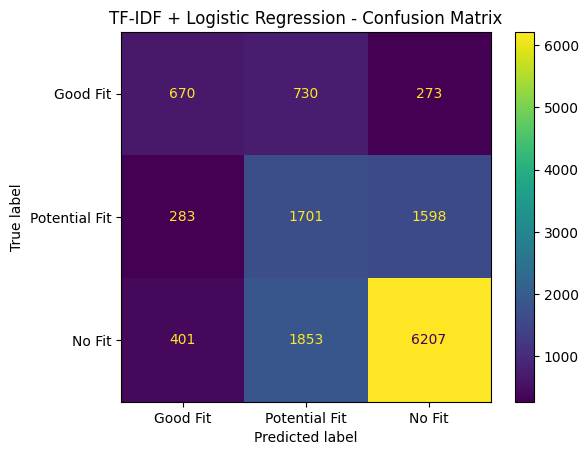

In [80]:
#where-it-is-making-mistakes

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    ml_prediction,
    labels=["Good Fit", "Potential Fit", "No Fit"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good Fit", "Potential Fit", "No Fit"]
)

disp.plot()
plt.title("TF-IDF + Logistic Regression - Confusion Matrix")
plt.show()

In [81]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train, y_train)

print("Linear SVM training completed.")

Linear SVM training completed.


In [82]:
svm_prediction = svm_model.predict(X_test)
print("SVM predictions generated.")

SVM predictions generated.


In [83]:
svm_accuracy = accuracy_score(y_test, svm_prediction)

svm_macro_f1 = f1_score(
    y_test,
    svm_prediction,
    average="macro"
)

print("TF-IDF + Linear SVM")
print("----------------------")
print("Accuracy:", svm_accuracy)
print("Macro-F1:", svm_macro_f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_prediction,
        zero_division=0
    )
)

TF-IDF + Linear SVM
----------------------
Accuracy: 0.6410761154855643
Macro-F1: 0.530901440747369

Classification Report:
               precision    recall  f1-score   support

     Good Fit       0.60      0.37      0.46      1673
       No Fit       0.73      0.82      0.77      8461
Potential Fit       0.38      0.34      0.36      3582

     accuracy                           0.64     13716
    macro avg       0.57      0.51      0.53     13716
 weighted avg       0.62      0.64      0.63     13716



In [84]:
model_comparison = pd.DataFrame({
    "Model": [
        "Level 0 - Majority",
        "Level 1 - Resume Domain",
        "TF-IDF + Logistic Regression",
        "TF-IDF + Linear SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, level0_prediction),
        accuracy_score(y_test, level1_prediction),
        ml_accuracy,
        svm_accuracy
    ],
    "Macro_F1": [
        f1_score(y_test, level0_prediction, average="macro"),
        f1_score(y_test, level1_prediction, average="macro"),
        ml_macro_f1,
        svm_macro_f1
    ]
})

model_comparison

,Model,Accuracy,Macro_F1
0,Level 0 - Majority,0.616871,0.254348
1,Level 1 - Resume Domain,0.616871,0.254348
2,TF-IDF + Logistic Regression,0.625401,0.541922
3,TF-IDF + Linear SVM,0.641076,0.530901


In [85]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(train_df["combined_text"])
X_test = tfidf.transform(test_df["combined_text"])

y_train = train_df["label"]
y_test = test_df["label"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (80017, 20000)
X_test shape: (13716, 20000)


In [87]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Take a representative 20,000-row sample
cv_sample = train_df.sample(
    n=20000,
    random_state=42
)

X_cv = tfidf.transform(cv_sample["combined_text"])
y_cv = cv_sample["label"]

print("Validation sample shape:", X_cv.shape)
print("Label distribution:")
print(y_cv.value_counts())

Validation sample shape: (20000, 20000)
Label distribution:
label
No Fit           14970
Potential Fit     3559
Good Fit          1471
Name: count, dtype: int64


In [5]:
lr_cv = cross_val_score(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    X_cv,
    y_cv,
    cv=3,
    scoring="f1_macro"
)

print("Logistic Regression 3-Fold Macro-F1:")
print(lr_cv)

print("Mean:", lr_cv.mean())
print("Std:", lr_cv.std())

NameError: name 'cross_val_score' is not defined

In [1]:
svm_cv = cross_val_score(
    LinearSVC(
        class_weight="balanced",
        random_state=42
    ),
    X_cv,
    y_cv,
    cv=3,
    scoring="f1_macro"
)

print("Linear SVM 3-Fold Macro-F1:")
print(svm_cv)

print("Mean:", svm_cv.mean())
print("Std:", svm_cv.std())

NameError: name 'cross_val_score' is not defined